# 3.9 Ensembles : trois façons de combiner des modèles

🖥️ [**Diapositives du cours, Séance 18 (lun. 9 nov.)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec18_robust_training.html)

Vendredi, une forêt moyennait de nombreux arbres construits indépendamment. C'est une façon de combiner des modèles. Le ***boosting*** construit les arbres en séquence, chacun corrigeant les erreurs laissées par les autres. Le ***stacking*** (empilement) entraîne un modèle final à pondérer plusieurs modèles différents. Les combinaisons gagnent souvent, et elles gagnent souvent de très peu : Feigl et al. (2021) ont comparé des forêts aléatoires, des arbres *boostés* et des réseaux de neurones sur la température des cours d'eau dans dix bassins versants, et ont trouvé que le choix des entrées comptait bien plus que la famille de modèles. Ce notebook Jupyter (carnet) vous permet de mesurer quand une combinaison aide, et pourquoi elle en est parfois incapable.

**Objectifs d'apprentissage.** À la fin de ce notebook, vous saurez :

1. moyenner les probabilités de différents modèles et noter le résultat ;
2. compter les erreurs que les modèles partagent, et dire pourquoi ces erreurs limitent un ensemble ;
3. écrire vous-même le *boosting* comme une boucle sur les résidus, et lire ses erreurs d'entraînement et sur données tenues à l'écart ;
4. empiler des modèles avec des prédictions hors pli ;
5. lire le désaccord entre modèles comme un avertissement sur une prédiction.

**Durée :** environ 15 minutes, à deux. Si le temps manque, sautez la partie 3.

## Comment fonctionne ce notebook

Chaque cellule **À vous** demande quelques lignes de code. Lisez l'indice, écrivez votre réponse à l'endroit indiqué dans la cellule et exécutez-la. La cellule suivante contient une solution détaillée, masquée tant que vous ne cliquez pas sur ⋯. Cette cellule masquée vérifie aussi votre réponse : elle affiche `correct` ou un indice, et si votre réponse manque ou diffère, elle utilise le résultat de référence pour que la suite du notebook s'exécute quand même. Votre propre réponse, si elle diffère, est conservée sous le même nom suivi de `_yours`.

In [1]:
# Data handling
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import pooch

# Plotting
import matplotlib.pyplot as plt

# Models and scores (scikit-learn)
from sklearn.datasets import make_classification   # synthetic stand-in if Zenodo cannot be reached
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, mean_absolute_error
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

Les valeurs ci-dessous servent à plusieurs endroits : elles sont donc définies une seule fois. Les couleurs des figures restent distinctes pour les personnes daltoniennes (la palette Okabe-Ito).

In [2]:
SEED = 42
SPLIT_SEED = 2026      # the canonical split of notebook 3.5
RATE, DEPTH = 0.3, 2   # Part 2: each boosting tree is shallow, and only part of its correction is kept
ROUNDS = 300
BLUE, RED, GRAY, MUTED = "#0072B2", "#D55E00", "#b8b1a4", "#6e675c"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Helper: compare an answer with a reference. If the answer is missing or different, print a hint and use the
# reference so the cells below still run; a different answer is kept as <name>_yours.
def check(name, ns, reference, hint, measure=None, tol=1e-3):
    measure = measure or (lambda value: np.asarray(value, dtype=float))
    yours = ns.get(name)
    if yours is None or (hasattr(yours, "__len__") and len(yours) == 0):
        print(f"{name}: not answered yet. Hint: {hint}\n  Using the reference result below.")
    else:
        try:
            ok = np.allclose(measure(yours), measure(reference), atol=tol)
        except Exception:
            ok = False
        if ok:
            print(f"{name}: correct")
            return
        print(f"{name}: not the expected result. Hint: {hint}\n  Your answer is kept as {name}_yours; "
              "the reference is used below.")
        ns[f"{name}_yours"] = yours
    ns[name] = reference

## Partie 1. Moyenner des modèles sur les types de sources sismiques

*Données :* 📍 Capteur in situ · 🪨 Terre solide · 📈 Sismologie

Nous revenons aux 4 000 événements du Nord-Ouest Pacifique de [3.5](3.5_multiclass_classification.ipynb) et du cours de vendredi : séismes, explosions, événements de surface et fenêtres de bruit (enregistrement Zenodo 14025693 ; carte dans Kharita et al., 2026, *Seismica*). Le découpage est le découpage canonique, 3 000 événements pour l'entraînement et 1 000 pour le test. Deviner toujours la même classe donne un macro-F1 de 0,10, puisque les classes sont équilibrées.

In [4]:
SEISMIC_FILES = {
    "1000_earthquakes_physical_features.csv": "md5:28129c8dd1b3e14f655d489577b841b5",
    "1000_explosion_physical_features.csv": "md5:af1342d32e163e961e043364136359b0",
    "1000_noise_physical_features.csv": "md5:16cdb992fed6cf6273d5624f5df905da",
    "1000_surface_physical_features.csv": "md5:9a2c2643030cf058704d68e130654e9d",
}
try:
    tables = [pd.read_csv(pooch.retrieve(url=f"https://zenodo.org/api/records/14025693/files/{name}/content",
                                         known_hash=checksum, fname=name, path=pooch.os_cache("mlgeo")), index_col=0)
              for name, checksum in SEISMIC_FILES.items()]
    seismic = pd.concat(tables, ignore_index=True).dropna(axis=1)
    X = seismic.drop(columns=["source", "serial_no"])
    y = seismic["source"]
except Exception as error:
    print(f"Zenodo could not be reached ({error}). Using SYNTHETIC events: the scores below will differ from the text.")
    values, codes = make_classification(n_samples=4000, n_features=61, n_informative=20, n_classes=4, random_state=SEED)
    X = pd.DataFrame(values, columns=[f"feature_{i}" for i in range(61)])
    y = pd.Series(np.array(["earthquake", "explosion", "noise", "surface event"])[codes])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SPLIT_SEED, stratify=y)
truth = y_test.to_numpy()
print(f"{len(X_train)} training events, {len(X_test)} test events, {X.shape[1]} waveform features")

3000 training events, 1000 test events, 61 waveform features


Nous ajustons trois types de modèles différents et conservons leurs probabilités de classe sur les événements de test. Le modèle *boosté* prend environ 10 secondes.

In [5]:
members = {"logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
           "forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
           "boosted": HistGradientBoostingClassifier(random_state=SEED)}
probabilities = {name: model.fit(X_train, y_train).predict_proba(X_test) for name, model in members.items()}
classes = members["forest"].classes_
labels = {name: classes[p.argmax(axis=1)] for name, p in probabilities.items()}
macro_f1 = {name: f1_score(truth, labels[name], average="macro") for name in members}
pd.Series(macro_f1).round(3).to_frame("macro-F1, test events")

,"macro-F1, test events"
logistic,0.884
forest,0.884
boosted,0.898


### À vous (1) : moyenner les trois modèles

Calculez `average_probability`, la moyenne des trois tableaux de probabilités, puis `average_f1`, le macro-F1 de la classe ayant la probabilité moyenne la plus élevée.

*Indice :* `(probabilities["logistic"] + probabilities["forest"] + probabilities["boosted"]) / 3`, puis `classes[average_probability.argmax(axis=1)]`, puis `f1_score(truth, ..., average="macro")`.

In [6]:
average_probability = None   # replace None with your expression
average_f1 = None            # replace None with your expression

*Solution détaillée ci-dessous (cliquez sur ⋯ pour l'ouvrir).*

In [7]:
average_probability_sol = (probabilities["logistic"] + probabilities["forest"] + probabilities["boosted"]) / 3
average_f1_sol = f1_score(truth, classes[average_probability_sol.argmax(axis=1)], average="macro")
check("average_probability", globals(), average_probability_sol, "add the three arrays and divide by 3.")
check("average_f1", globals(), average_f1_sol, "take argmax across classes, map it to names with classes[...], then score.")
print(f"Equal average: macro-F1 {average_f1:.3f}. Best single model: {max(macro_f1.values()):.3f}")

average_probability: not answered yet. Hint: add the three arrays and divide by 3.
  Using the reference result below.
average_f1: not answered yet. Hint: take argmax across classes, map it to names with classes[...], then score.
  Using the reference result below.
Equal average: macro-F1 0.898. Best single model: 0.898


### À vous (2) : quelles erreurs les modèles partagent-ils ?

Un ensemble ne peut réparer que les erreurs que ses membres ne partagent pas. `wrong` ci-dessous indique, pour chaque modèle, les événements de test sur lesquels il se trompe. Calculez `all_three_wrong`, le nombre d'événements que les trois modèles classent mal.

*Indice :* combinez les trois tableaux avec `&`, puis utilisez `.sum()`.

In [8]:
wrong = {name: labels[name] != truth for name in members}
print({name: int(w.sum()) for name, w in wrong.items()})

all_three_wrong = None   # replace None with your expression

{'logistic': 116, 'forest': 115, 'boosted': 102}


*Solution détaillée ci-dessous (cliquez sur ⋯ pour l'ouvrir).*

In [9]:
all_three_wrong_sol = int((wrong["logistic"] & wrong["forest"] & wrong["boosted"]).sum())
check("all_three_wrong", globals(), all_three_wrong_sol, "wrong['logistic'] & wrong['forest'] & wrong['boosted'], then .sum().")
print(f"{all_three_wrong} events fool all three models")
agree = (labels["logistic"] == labels["forest"]) & (labels["forest"] == labels["boosted"])
average_labels = classes[average_probability.argmax(axis=1)]
print(f"Models agree on {agree.sum()} events: {(average_labels != truth)[agree].mean():.0%} of them wrong")
print(f"Models disagree on {(~agree).sum()} events: {(average_labels != truth)[~agree].mean():.0%} of them wrong")

all_three_wrong: not answered yet. Hint: wrong['logistic'] & wrong['forest'] & wrong['boosted'], then .sum().
  Using the reference result below.
62 events fool all three models
Models agree on 893 events: 6% of them wrong
Models disagree on 107 events: 42% of them wrong


**Pause et discussion.**

- La plupart des erreurs sont partagées. Que pourraient être ces événements, physiquement ? Un meilleur modèle pourrait-il les corriger ?
- Quand les trois modèles sont en désaccord, la moyenne se trompe bien plus souvent. Que feriez-vous de ces événements dans un catalogue opérationnel ?

:::{dropdown} Points à faire ressortir
Les erreurs partagées désignent les données plutôt que le modèle : des événements dont les caractéristiques de forme d'onde ressemblent à une autre classe, ou des étiquettes que l'équipe d'analyse pourrait réviser. Aucune combinaison de ces modèles ne peut les corriger. Le désaccord reste utile même quand la moyenne n'est pas plus exacte, car il classe les prédictions selon la confiance à leur accorder, et les événements à faible accord sont ceux à transmettre à l'équipe d'analyse.
:::

```{admonition} Incertitude épistémique et incertitude aléatoire
:class: note
Le désaccord entre modèles estime l'incertitude **épistémique** : celle qui vient de ce que les modèles n'ont pas appris, et qui diminue quand les données d'entraînement augmentent. Il ne capte pas l'incertitude **aléatoire** : le caractère aléatoire de la mesure elle-même, comme le bruit du capteur, qu'aucune quantité de données d'entraînement ne supprime. Les deux termes sont définis dans le [glossaire](../reference/glossary.md). La dispersion des votes d'une forêt (diapositive de vendredi) et celle des ensembles profonds de la leçon 4.5 se lisent de la même façon.
```

## Partie 2. Le *boosting* à la main : la température du sol à partir de la température de l'air

*Données :* 📍 Capteur in situ · 💧 Eaux continentales · 💧 Hydrologie et modélisation des surfaces continentales

Retour à la station USCRN WA Spokane 17 SSW, dans l'est de l'État de Washington (carte dans [3.11, en anglais](https://geo-smart.github.io/mlgeo-book/forests-practice/)). La température maximale journalière du sol suit la température maximale journalière de l'air : une seule caractéristique suffit donc pour voir le travail de chaque arbre. Nous entraînons sur 2015 à 2021 et tenons à l'écart 2022 à 2024.

Un modèle *boosté* part de la moyenne, ajuste un petit arbre à ce qui reste faux, ajoute une partie de la prédiction de cet arbre, et recommence.

In [10]:
SNAPSHOTS = Path("../Chapter2-DataManipulation/snapshots")
BASE_URL = "https://raw.githubusercontent.com/geo-smart/mlgeo-book/main/book/Chapter2-DataManipulation/snapshots/"
FINGERPRINTS = {
    "uscrn_WA_Spokane_17_SSW_2015-2024.txt": "115f60bc36f8aed6ea8d916da42b5e14bb0a5361ecbf055b6cbbedba64dc994e",
    "uscrn_daily01_HEADERS.txt": "dde1b4d78d6b68b9a558d042876340c0476b73c962896ff1b152e8e49379946e",
}


def course_file(name):
    path = SNAPSHOTS / name
    if not path.exists():
        path = Path(name)
        if not path.exists():
            urllib.request.urlretrieve(BASE_URL + name, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != FINGERPRINTS[name]:
        raise ValueError(f"{path} is not the course copy. Delete it, or restore it with git, and run this cell again.")
    return path


columns = course_file("uscrn_daily01_HEADERS.txt").read_text().splitlines()[1].split()
station = pd.read_csv(course_file("uscrn_WA_Spokane_17_SSW_2015-2024.txt"), sep=r"\s+", names=columns, dtype={"LST_DATE": str},
                      na_values=[-9999, -99, -9999.0, -99.0, -99.000])
station["date"] = pd.to_datetime(station["LST_DATE"])
surface = station.set_index("date")[["T_DAILY_MAX", "SUR_TEMP_DAILY_MAX"]].dropna()
surface.columns = ["air", "ground"]
fit, held = surface[:"2021"], surface["2022":]
print(f"{len(fit)} training days, {len(held)} held-out days")

2550 training days, 1088 held-out days


### À vous (3) : la boucle de *boosting*

Complétez la boucle dans `boost`. À chaque tour : calculez les résidus des jours d'entraînement, ajustez-leur un `DecisionTreeRegressor(max_depth=DEPTH)`, et ajoutez `RATE` fois sa prédiction aux deux prédictions courantes.

*Indice :* `tree = DecisionTreeRegressor(max_depth=DEPTH, random_state=SEED).fit(fit[["air"]], fit["ground"] - fit_prediction)`, puis `fit_prediction += RATE * tree.predict(fit[["air"]])`, et de même avec `held`.

In [11]:
def boost(fit, held, rounds):
    fit_prediction = np.full(len(fit), fit["ground"].mean())
    held_prediction = np.full(len(held), fit["ground"].mean())
    errors = []
    for _ in range(rounds):
        # your code here: three lines (fit a tree to the residuals, update fit_prediction, update held_prediction)

        errors.append((mean_absolute_error(fit["ground"], fit_prediction), mean_absolute_error(held["ground"], held_prediction)))
    return np.array(errors)

*Solution détaillée ci-dessous (cliquez sur ⋯ pour l'ouvrir).*

In [12]:
def boost_sol(fit, held, rounds):
    fit_prediction = np.full(len(fit), fit["ground"].mean())
    held_prediction = np.full(len(held), fit["ground"].mean())
    errors = []
    for _ in range(rounds):
        tree = DecisionTreeRegressor(max_depth=DEPTH, random_state=SEED).fit(fit[["air"]], fit["ground"] - fit_prediction)
        fit_prediction += RATE * tree.predict(fit[["air"]])
        held_prediction += RATE * tree.predict(held[["air"]])
        errors.append((mean_absolute_error(fit["ground"], fit_prediction), mean_absolute_error(held["ground"], held_prediction)))
    return np.array(errors)


check("boost", globals(), boost_sol, "the tree is fit to fit['ground'] - fit_prediction; both predictions then add RATE times the tree's output.",
      measure=lambda f: f(fit, held, 10)[-1], tol=0.01)
errors = boost(fit, held, ROUNDS)
for r in (1, 3, 10, 300):
    print(f"{r:3d} trees: training error {errors[r - 1, 0]:.2f} °C, held-out error {errors[r - 1, 1]:.2f} °C")

boost: not the expected result. Hint: the tree is fit to fit['ground'] - fit_prediction; both predictions then add RATE times the tree's output.
  Your answer is kept as boost_yours; the reference is used below.


  1 trees: training error 12.16 °C, held-out error 10.95 °C
  3 trees: training error 7.30 °C, held-out error 6.23 °C
 10 trees: training error 4.06 °C, held-out error 4.08 °C
300 trees: training error 3.68 °C, held-out error 4.27 °C


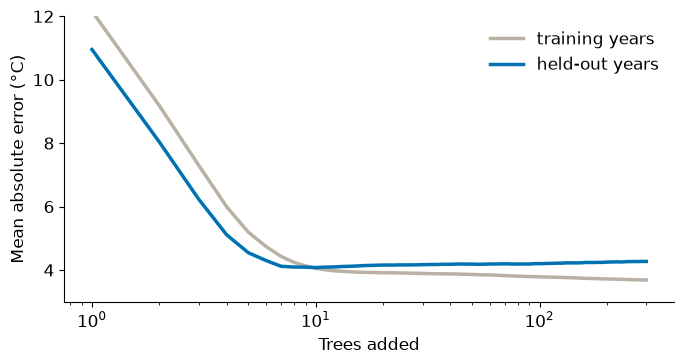

In [13]:
# Helper: training and held-out error against the number of trees.
def plot_boosting():
    fig, ax = plt.subplots(figsize=(7, 3.8))
    rounds = np.arange(1, len(errors) + 1)
    ax.plot(rounds, errors[:, 0], color=GRAY, lw=2.5, label="training years")
    ax.plot(rounds, errors[:, 1], color=BLUE, lw=2.5, label="held-out years")
    ax.set(xscale="log", xlabel="Trees added", ylabel="Mean absolute error (°C)", ylim=(3, 12))
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


plot_boosting()

**Pause et discussion.**

- Ajouter des arbres à une forêt ne lui nuit pas. Pourquoi ajouter des arbres à un modèle *boosté* peut-il lui nuire ?
- Comment choisiriez-vous le nombre d'arbres sans regarder les années tenues à l'écart ?

:::{dropdown} Points à faire ressortir
Une forêt moyenne des arbres indépendants : davantage d'arbres ne font donc que stabiliser la moyenne. Le *boosting* continue d'ajuster ce qui reste, et une fois le signal épuisé, ce qui reste est du bruit. L'erreur d'entraînement continue de baisser tandis que l'erreur sur les années tenues à l'écart remonte après environ 10 arbres. Le nombre d'arbres est donc un réglage à choisir par validation croisée à l'intérieur des années d'entraînement, avec des plis qui respectent le temps, comme en 3.8. En pratique, utilisez `HistGradientBoostingRegressor` ou `HistGradientBoostingClassifier`, la même idée avec des arbres plus rapides et un arrêt précoce (*early stopping*).
:::

## Partie 3. *Stacking* : entraîner un modèle sur les modèles

Le *stacking* remplace la moyenne à poids égaux par un petit modèle qui apprend quelle confiance accorder à chaque membre. Il doit apprendre à partir de prédictions sur des événements sur lesquels les membres ne se sont pas entraînés, sinon il ferait le plus confiance aux membres qui ont le plus mémorisé leurs données d'entraînement. `cross_val_predict` fournit ces prédictions **hors pli** (*out-of-fold*). Cette cellule prend environ 30 secondes.

In [14]:
out_of_fold = {name: cross_val_predict(model, X_train, y_train, cv=3, method="predict_proba") for name, model in members.items()}
stack_inputs_train = np.hstack(list(out_of_fold.values()))
stack_inputs_test = np.hstack(list(probabilities.values()))
print(stack_inputs_train.shape, stack_inputs_test.shape)

(3000, 12) (1000, 12)


### À vous (4) : ajuster le *stacking*

Ajustez un `LogisticRegression(max_iter=5000)` sur `stack_inputs_train` et `y_train`, prédisez sur `stack_inputs_test`, et calculez `stack_f1`, le macro-F1 sur les événements de test.

*Indice :* `LogisticRegression(max_iter=5000).fit(stack_inputs_train, y_train).predict(stack_inputs_test)`.

In [15]:
stack_f1 = None   # replace None with your expression

*Solution détaillée ci-dessous (cliquez sur ⋯ pour l'ouvrir).*

In [16]:
stack_f1_sol = f1_score(truth, LogisticRegression(max_iter=5000).fit(stack_inputs_train, y_train).predict(stack_inputs_test), average="macro")
check("stack_f1", globals(), stack_f1_sol, "fit on the out-of-fold inputs, predict on the test inputs, then use f1_score with average='macro'.")
summary = pd.Series({**macro_f1, "equal average": average_f1, "stack": stack_f1}).round(3)
summary.to_frame("macro-F1, test events")

stack_f1: not answered yet. Hint: fit on the out-of-fold inputs, predict on the test inputs, then use f1_score with average='macro'.
  Using the reference result below.


,"macro-F1, test events"
logistic,0.884
forest,0.884
boosted,0.898
equal average,0.898
stack,0.896


Sur ce découpage, le modèle *boosté*, la moyenne à poids égaux et le *stacking* sont à 0,002 près les uns des autres, soit environ deux événements sur mille, bien trop peu pour les départager. C'est un résultat utile. Avant de recourir au *stacking*, comparez-le à son meilleur membre et à une moyenne à poids égaux, à l'intérieur des données d'entraînement.

## Résumé

| Méthode | En quoi les membres diffèrent | Comment ils se combinent | Principal réglage à surveiller | scikit-learn |
|---|---|---|---|---|
| **Vote ou moyenne** | différents types de modèles | vote à égalité ou probabilité moyenne | si les membres font des erreurs différentes | `VotingClassifier` |
| ***Bagging*, forêts** | même modèle sur des données rééchantillonnées | vote ou moyenne | taille des arbres | `BaggingClassifier`, `RandomForestClassifier` |
| ***Boosting*** | chaque arbre ajuste les erreurs restantes | somme pondérée | nombre d'arbres, taux d'apprentissage | `HistGradientBoostingClassifier`, `AdaBoostClassifier` |
| ***Stacking*** | différents types de modèles | un modèle entraîné sur des prédictions hors pli | fuite de données par les prédictions sur l'échantillon d'entraînement | `StackingClassifier` |

**Suite.** [3.10](3.10_autoML.ipynb) laisse une recherche choisir parmi ces modèles, et demande sur quoi elle est notée.